<a href="https://colab.research.google.com/github/difanaya/PCVK_Ganjil_2026/blob/main/Modul5/Modul5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modul 5 - Histogram, Histogram Equalization, dan Dithering

**Nama :** Difa Naya Sari Pasha

**NIM :** 244107020213


## Setup

In [2]:
NAMA = 'Difa Naya Sari Pasha'
NIM  = '244107020213'

N     = int(NIM[-3:])
PARAM = {
    'bins' : 2 ** ((N % 4) + 3),
    'clip' : round(1.0 + (N % 5) * 0.5, 1),
    'tile' : (N % 4) + 2,
    'L'    : 2 ** ((N % 3) + 1),
}

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
import math
from google.colab.patches import cv2_imshow

In [3]:
from google.colab import drive
drive.mount('/content/drive')

CONTOH = '/content/drive/MyDrive/PCVK/Images'            # citra contoh bersama
BASE   = '/content/drive/MyDrive/PCVK/Images/' + NIM     # citra KTM milik Anda
print('CONTOH :', CONTOH)
print('BASE   :', BASE)

CONTOH : /content/drive/MyDrive/PCVK/Images
BASE   : /content/drive/MyDrive/PCVK/Images/244107020213


## Fungsi Bantu

In [4]:
def tampil(img1, img2, judul1='asli', judul2='hasil'):
    plt.figure(figsize=(11, 4.5))
    for i, (im, jd) in enumerate([(img1, judul1), (img2, judul2)], 1):
        plt.subplot(1, 2, i)
        if im.ndim == 2:
            plt.imshow(im, cmap='gray', vmin=0, vmax=255)
        else:
            plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
        plt.title(jd)
        plt.axis('off')
    plt.show()


def histogram_manual(img, L=256):
    h = np.zeros(L, dtype=np.int64)        # 1. siapkan penghitung, isi 0
    for y in range(img.shape[0]):          # 2. telusuri setiap baris
        for x in range(img.shape[1]):      #    dan setiap kolom
            h[img[y, x]] += 1              # 3. tambah 1 sesuai nilai piksel
    return h


def PSNR(img1, img2):
    mse = np.mean((img1.astype(float) - img2.astype(float)) ** 2)
    if mse == 0:                           # tidak ada perbedaan sama sekali
        return 100
    return 20 * math.log10(255.0 / math.sqrt(mse))


def geser_hue(asli, hasil):
    h1 = cv.cvtColor(asli,  cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    d  = np.abs(h1 - h2)
    d  = np.minimum(d, 180 - d)          # Hue melingkar 0-179
    return d.mean()

## E-1 Percobaan Histogram

### Tahap 1 - citra contoh `lena.jpg`

Membuat histogram manual (perulangan bersarang), lalu membuktikan hasilnya sama persis
dengan `numpy.histogram` dan `cv.calcHist`.

lena.jpg  selisih maks manual vs numpy : 0
lena.jpg  selisih maks manual vs cv2   : 0


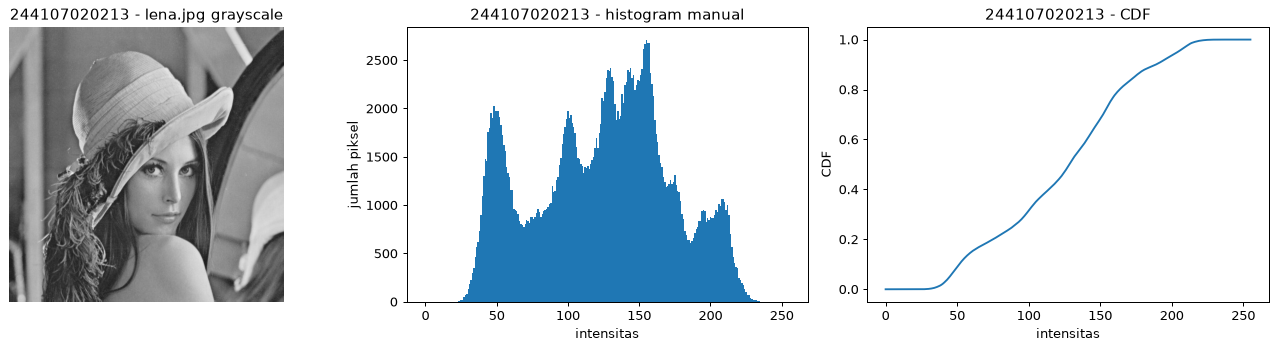

In [5]:
gray = cv.imread(CONTOH + '/lena.jpg', cv.IMREAD_GRAYSCALE)
h    = histogram_manual(gray)
p    = h / gray.size                       # normalisasi, jumlahnya = 1
cdf  = np.cumsum(p)                        # distribusi kumulatif
assert h.sum() == gray.size                # pemeriksaan wajib

h_np = np.histogram(gray.ravel(), bins=256, range=(0, 256))[0]
h_cv = cv.calcHist([gray], [0], None, [256], [0, 256]).ravel().astype(np.int64)
print('lena.jpg  selisih maks manual vs numpy :', np.abs(h - h_np).max())
print('lena.jpg  selisih maks manual vs cv2   :', np.abs(h - h_cv).max())

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.imshow(gray, cmap='gray', vmin=0, vmax=255)
plt.title(NIM + ' - lena.jpg grayscale')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.bar(np.arange(256), h, width=1)
plt.title(NIM + ' - histogram manual')
plt.xlabel('intensitas')
plt.ylabel('jumlah piksel')
plt.subplot(1, 3, 3)
plt.plot(cdf)
plt.title(NIM + ' - CDF')
plt.xlabel('intensitas')
plt.ylabel('CDF')
plt.tight_layout()
plt.show()

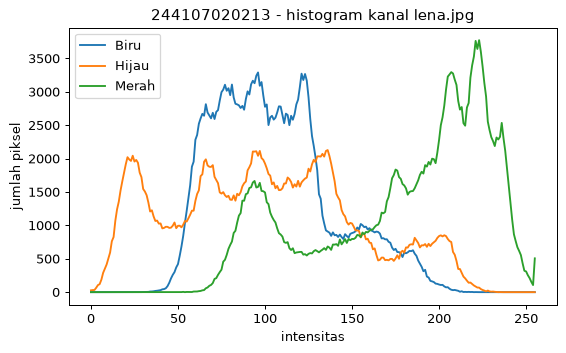

In [6]:
# citra berwarna: ulangi untuk tiap kanal
bgr = cv.imread(CONTOH + '/lena.jpg')
plt.figure(figsize=(7, 4))
for i, nama in enumerate(['Biru', 'Hijau', 'Merah']):
    plt.plot(histogram_manual(bgr[:, :, i]), label=nama)
plt.title(NIM + ' - histogram kanal lena.jpg')
plt.xlabel('intensitas')
plt.ylabel('jumlah piksel')
plt.legend()
plt.show()

### Tahap 2 - citra KTM sendiri `KTM1b.jpg`

KTM1b.jpg selisih maks manual vs numpy : 0
KTM1b.jpg selisih maks manual vs cv2   : 0


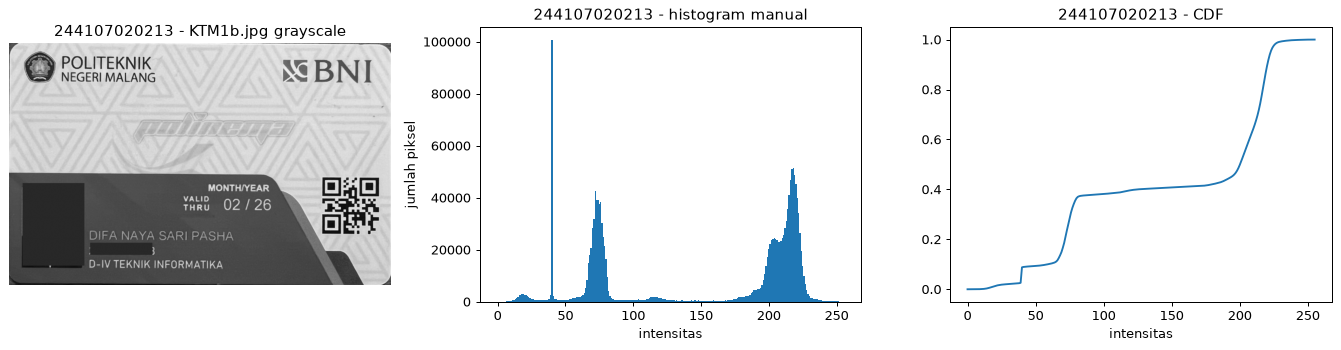

In [7]:
gray_ktm = cv.imread(BASE + '/KTM1b.jpg', cv.IMREAD_GRAYSCALE)
h_ktm    = histogram_manual(gray_ktm)
h_ktm_np = np.histogram(gray_ktm.ravel(), bins=256, range=(0, 256))[0]
h_ktm_cv = cv.calcHist([gray_ktm], [0], None, [256], [0, 256]).ravel().astype(np.int64)
assert h_ktm.sum() == gray_ktm.size

print('KTM1b.jpg selisih maks manual vs numpy :', np.abs(h_ktm - h_ktm_np).max())
print('KTM1b.jpg selisih maks manual vs cv2   :', np.abs(h_ktm - h_ktm_cv).max())

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.imshow(gray_ktm, cmap='gray', vmin=0, vmax=255)
plt.title(NIM + ' - KTM1b.jpg grayscale')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.bar(np.arange(256), h_ktm, width=1)
plt.title(NIM + ' - histogram manual')
plt.xlabel('intensitas')
plt.ylabel('jumlah piksel')
plt.subplot(1, 3, 3)
plt.plot(np.cumsum(h_ktm / h_ktm.sum()))
plt.title(NIM + ' - CDF')
plt.xlabel('intensitas')
plt.tight_layout()
plt.show()

### PERTANYAAN PRAKTIKUM E1

**1. Bandingkan histogram manual, `numpy.histogram`, dan `cv.calcHist`.**

Hasil di atas: selisih maksimumnya 0 untuk `lena.jpg` maupun `KTM1b.jpg`. Artinya ketiganya
menghitung hal yang sama, cuma caranya beda (manual pakai for bersarang, numpy vektor, cv2 internal).
Jadi histogram manual saya sudah benar, dan `np.histogram`/`cv.calcHist` aman dipakai karena jauh
lebih cepat di citra besar.

**2. Gambarkan histogram ternormalisasi p(j) dan kurva CDF KTM1a-KTM1d dalam satu figure 2x2, lalu jelaskan perbedaannya.**

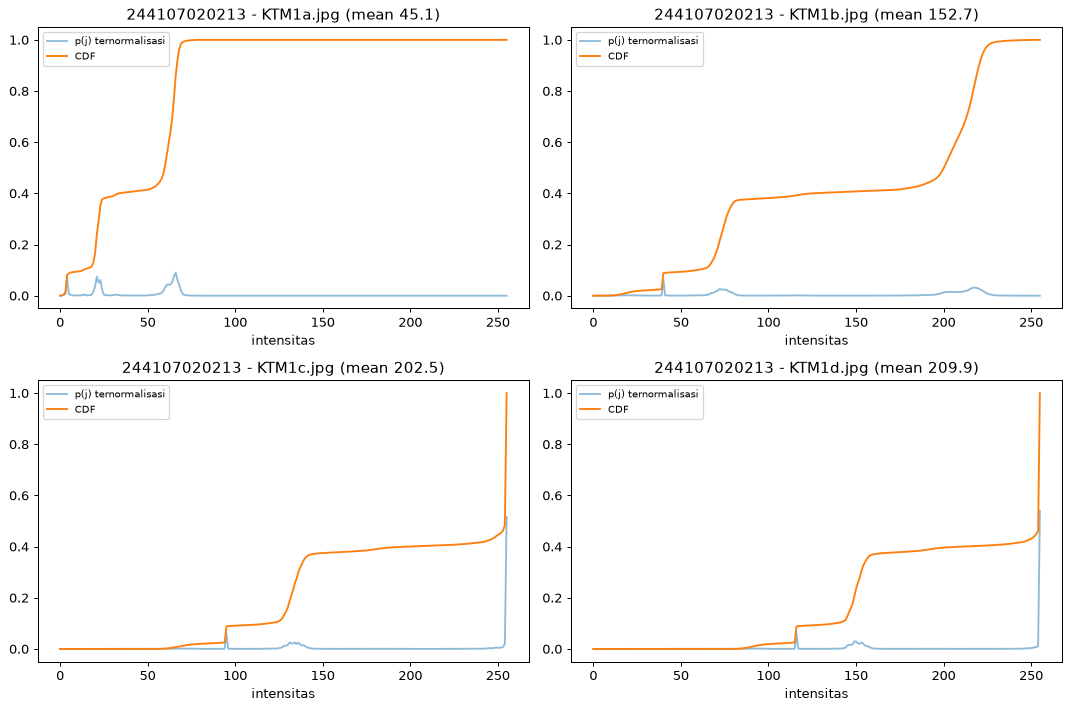

In [8]:
berkas = ['KTM1a.jpg', 'KTM1b.jpg', 'KTM1c.jpg', 'KTM1d.jpg']
plt.figure(figsize=(12, 8))
for i, nm in enumerate(berkas):
    g = cv.imread(BASE + '/' + nm, cv.IMREAD_GRAYSCALE)
    pr = histogram_manual(g) / g.size
    plt.subplot(2, 2, i + 1)
    plt.plot(pr, alpha=0.5, label='p(j) ternormalisasi')
    plt.plot(np.cumsum(pr), label='CDF')
    plt.title(NIM + ' - ' + nm + ' (mean %.1f)' % g.mean())
    plt.xlabel('intensitas')
    plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

Kurva CDF citra paling gelap (`KTM1a.jpg`, ruangan gelap) naik tajam di intensitas rendah lalu
datar, tanda pikselnya numpuk di area gelap. Kurva citra paling terang (`KTM1d.jpg`, cahaya matahari)
baru naik di intensitas tinggi dan lebih landai, tanda pikselnya geser ke area terang. Jadi bentuk CDF
langsung kebaca kondisi pencahayaan waktu foto diambil.

**3. Ulangi histogram KTM1b.jpg dengan `PARAM['bins']` bin dan dengan 256 bin.**

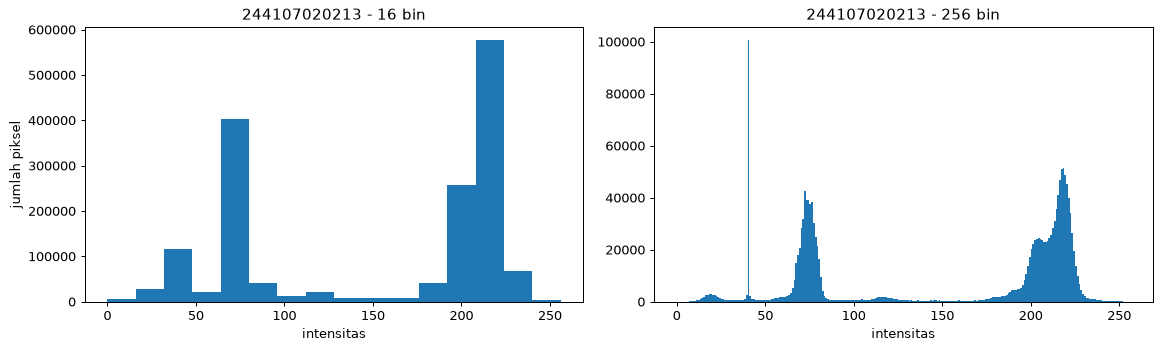

In [9]:
g = cv.imread(BASE + '/KTM1b.jpg', cv.IMREAD_GRAYSCALE)
plt.figure(figsize=(13, 4))
plt.subplot(1, 2, 1)
plt.hist(g.ravel(), bins=PARAM['bins'], range=(0, 256))
plt.title(NIM + ' - ' + str(PARAM['bins']) + ' bin')
plt.xlabel('intensitas')
plt.ylabel('jumlah piksel')
plt.subplot(1, 2, 2)
plt.hist(g.ravel(), bins=256, range=(0, 256))
plt.title(NIM + ' - 256 bin')
plt.xlabel('intensitas')
plt.tight_layout()
plt.show()

Dengan 256 bin, tiap nilai intensitas punya bin sendiri jadi sebarannya kelihatan halus. Pas
jumlah bin dikurangi jadi `PARAM['bins']` (=16), beberapa nilai digabung ke satu bin, puncaknya jadi
lebih tinggi/gemuk dan info detail intensitas mana yang dominan hilang. Jadi makin sedikit bin, makin
banyak detail yang hilang.

## E-2 Percobaan Histogram Equalization

### Fungsi Histogram Equalization manual

In [10]:
def histogram_equalization(gray, L=256):
    h     = histogram_manual(gray, L)
    cdf   = np.cumsum(h)
    cdf_m = cdf[cdf > 0].min()               # CDF minimum yang bukan nol
    total = gray.size
    lut   = np.round((cdf - cdf_m) / (total - cdf_m) * (L - 1)).astype(np.uint8)
    return lut[gray]

### Tahap 1 - citra contoh `lena_lc.jpg`

lena_lc.jpg selisih maks manual vs cv.equalizeHist : 0


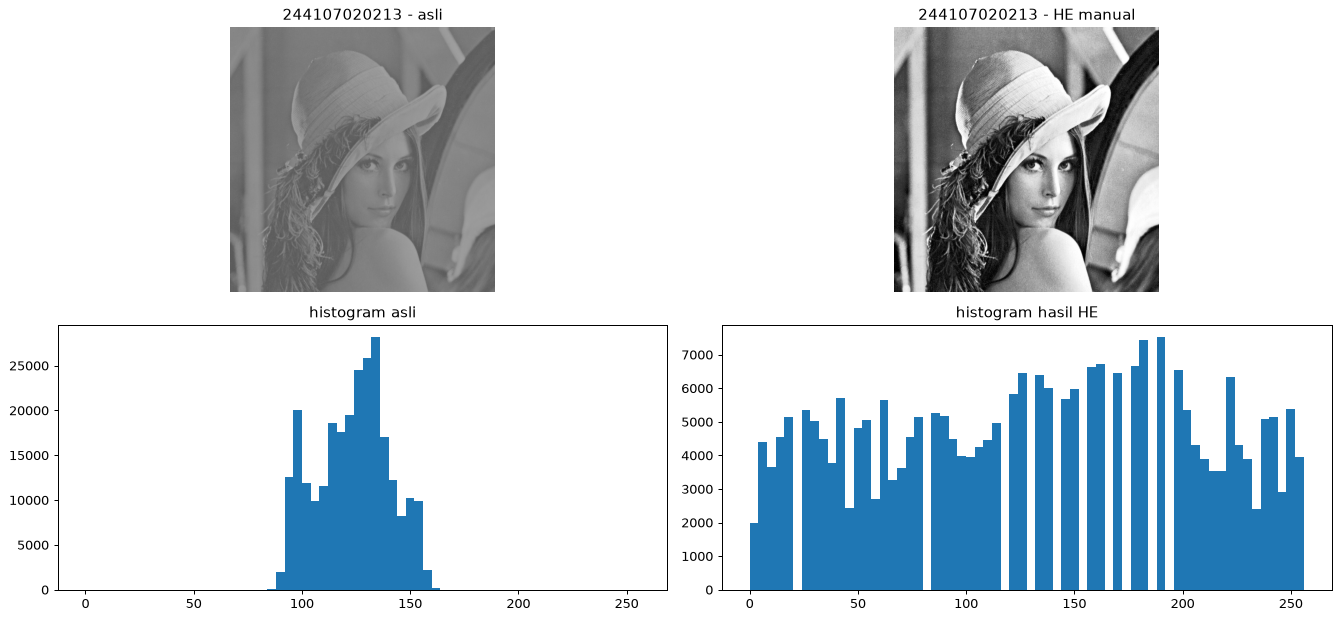

In [11]:
lc    = cv.imread(CONTOH + '/lena_lc.jpg', cv.IMREAD_GRAYSCALE)
he    = histogram_equalization(lc)
he_cv = cv.equalizeHist(lc)
print('lena_lc.jpg selisih maks manual vs cv.equalizeHist :',
      np.abs(he.astype(int) - he_cv.astype(int)).max())

plt.figure(figsize=(15, 7))
plt.subplot(2, 2, 1)
plt.imshow(lc, cmap='gray', vmin=0, vmax=255)
plt.title(NIM + ' - asli')
plt.axis('off')
plt.subplot(2, 2, 2)
plt.imshow(he, cmap='gray', vmin=0, vmax=255)
plt.title(NIM + ' - HE manual')
plt.axis('off')
plt.subplot(2, 2, 3)
plt.hist(lc.ravel(), bins=64, range=(0, 256))
plt.title('histogram asli')
plt.subplot(2, 2, 4)
plt.hist(he.ravel(), bins=64, range=(0, 256))
plt.title('histogram hasil HE')
plt.tight_layout()
plt.show()

### Tahap 2 - citra KTM sendiri `KTM1a.jpg`

KTM1a.jpg selisih maks manual vs cv.equalizeHist : 0


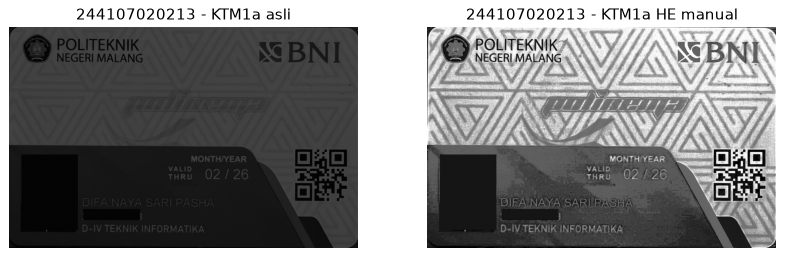

In [12]:
ktm   = cv.imread(BASE + '/KTM1a.jpg', cv.IMREAD_GRAYSCALE)
he_k  = histogram_equalization(ktm)
he_kc = cv.equalizeHist(ktm)
print('KTM1a.jpg selisih maks manual vs cv.equalizeHist :',
      np.abs(he_k.astype(int) - he_kc.astype(int)).max())
tampil(ktm, he_k, NIM + ' - KTM1a asli', NIM + ' - KTM1a HE manual')

### Ekualisasi pada citra berwarna

Cara 1 mengekualisasi kanal B, G, R satu per satu. Cara 2 hanya mengekualisasi kanal terang
(Y pada YCrCb, V pada HSV, L pada LAB) sehingga informasi warna tidak ikut bergeser.

Cara                    geser Hue (der)    rerata terang
Asli                               0.00            124.2
Ekualisasi B, G, R                75.01            128.3
Kanal Y                            1.71            128.0
Kanal V                            0.65             91.6
Kanal L                            2.65            121.8


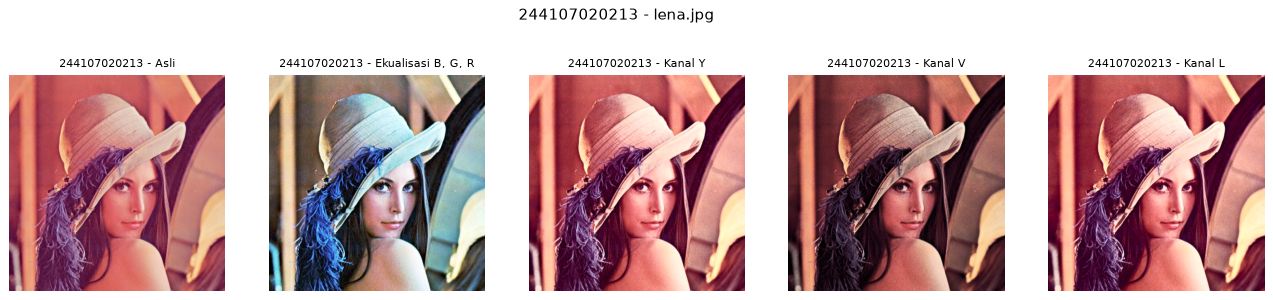

In [13]:
def analisis_ekualisasi_warna(berkas, label):
    bgr = cv.imread(berkas)

    # cara 1: tiap kanal diekualisasi sendiri-sendiri
    kanal = list(cv.split(bgr))
    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])
    he_rgb = cv.merge(kanal)

    # cara 2: hanya kanal terang yang diekualisasi
    ycrcb      = cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb)
    y, cr, cb  = cv.split(ycrcb)
    he_y = cv.cvtColor(cv.merge([cv.equalizeHist(y), cr, cb]), cv.COLOR_YCrCb2BGR)

    hsv        = cv.cvtColor(bgr, cv.COLOR_BGR2HSV)
    h, sat, v  = cv.split(hsv)
    he_v = cv.cvtColor(cv.merge([h, sat, cv.equalizeHist(v)]), cv.COLOR_HSV2BGR)

    lab        = cv.cvtColor(bgr, cv.COLOR_BGR2LAB)
    l, a, b    = cv.split(lab)
    he_l = cv.cvtColor(cv.merge([cv.equalizeHist(l), a, b]), cv.COLOR_LAB2BGR)

    judul = ['Asli', 'Ekualisasi B, G, R', 'Kanal Y', 'Kanal V', 'Kanal L']
    citra = [bgr, he_rgb, he_y, he_v, he_l]

    plt.figure(figsize=(18, 4))
    for i, (c, t) in enumerate(zip(citra, judul), 1):
        plt.subplot(1, 5, i)
        plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
        plt.title(NIM + ' - ' + t, fontsize=9)
        plt.axis('off')
    plt.suptitle(NIM + ' - ' + label)
    plt.show()

    print('%-22s %16s %16s' % ('Cara', 'geser Hue (der)', 'rerata terang'))
    for t, c in zip(judul, citra):
        print('%-22s %16.2f %16.1f' % (t, geser_hue(bgr, c) * 2,
                                       cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()))
    return citra


# tahap 1: citra contoh
_ = analisis_ekualisasi_warna(CONTOH + '/lena.jpg', 'lena.jpg')

Cara                    geser Hue (der)    rerata terang
Asli                               0.00            209.8
Ekualisasi B, G, R                18.93            170.1
Kanal Y                            1.96            163.5
Kanal V                            0.90            180.9
Kanal L                            5.55            161.2


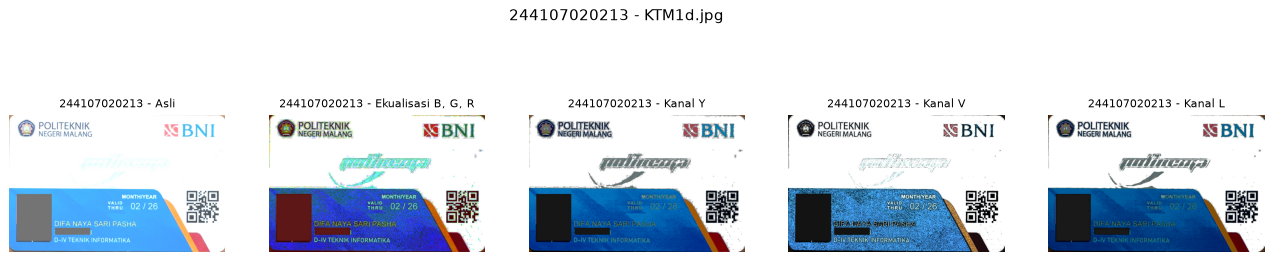

In [14]:
# tahap 2: citra KTM
_ = analisis_ekualisasi_warna(BASE + '/KTM1d.jpg', 'KTM1d.jpg')

### CLAHE pada kanal terang

Mengganti `cv.equalizeHist` dengan CLAHE (`clipLimit = PARAM['clip']`,
`tileGridSize = (PARAM['tile'], PARAM['tile'])`).

Cara                    geser Hue (der)    rerata terang
Global equalizeHist                1.96            163.5
CLAHE clip 2.5                     0.78            205.1


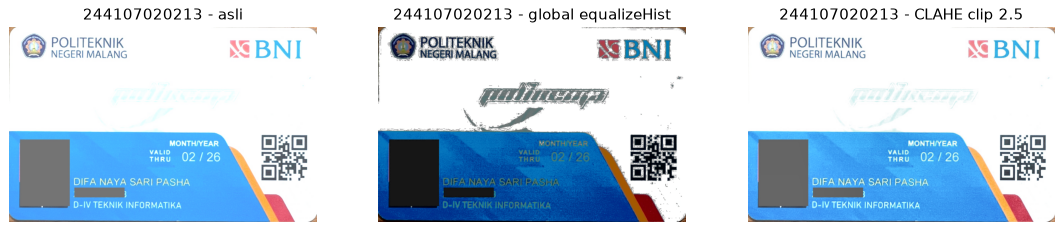

In [15]:
bgr = cv.imread(BASE + '/KTM1d.jpg')
y, cr, cb = cv.split(cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb))

he_y  = cv.cvtColor(cv.merge([cv.equalizeHist(y), cr, cb]), cv.COLOR_YCrCb2BGR)
clahe = cv.createCLAHE(clipLimit=PARAM['clip'], tileGridSize=(PARAM['tile'], PARAM['tile']))
cla_y = cv.cvtColor(cv.merge([clahe.apply(y), cr, cb]), cv.COLOR_YCrCb2BGR)

print('%-22s %16s %16s' % ('Cara', 'geser Hue (der)', 'rerata terang'))
for t, c in [('Global equalizeHist', he_y),
             ('CLAHE clip ' + str(PARAM['clip']), cla_y)]:
    print('%-22s %16.2f %16.1f' % (t, geser_hue(bgr, c) * 2,
                                   cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()))

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.imshow(cv.cvtColor(bgr, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - asli')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(cv.cvtColor(he_y, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - global equalizeHist')
plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(cv.cvtColor(cla_y, cv.COLOR_BGR2RGB))
plt.title(NIM + ' - CLAHE clip ' + str(PARAM['clip']))
plt.axis('off')
plt.show()

### PERTANYAAN PRAKTIKUM E2

**1. Ekualisasi global pada citra KTM (KTM1a.jpg) dan PSNR.**

PSNR KTM1a asli vs hasil ekualisasi : 7.84 dB


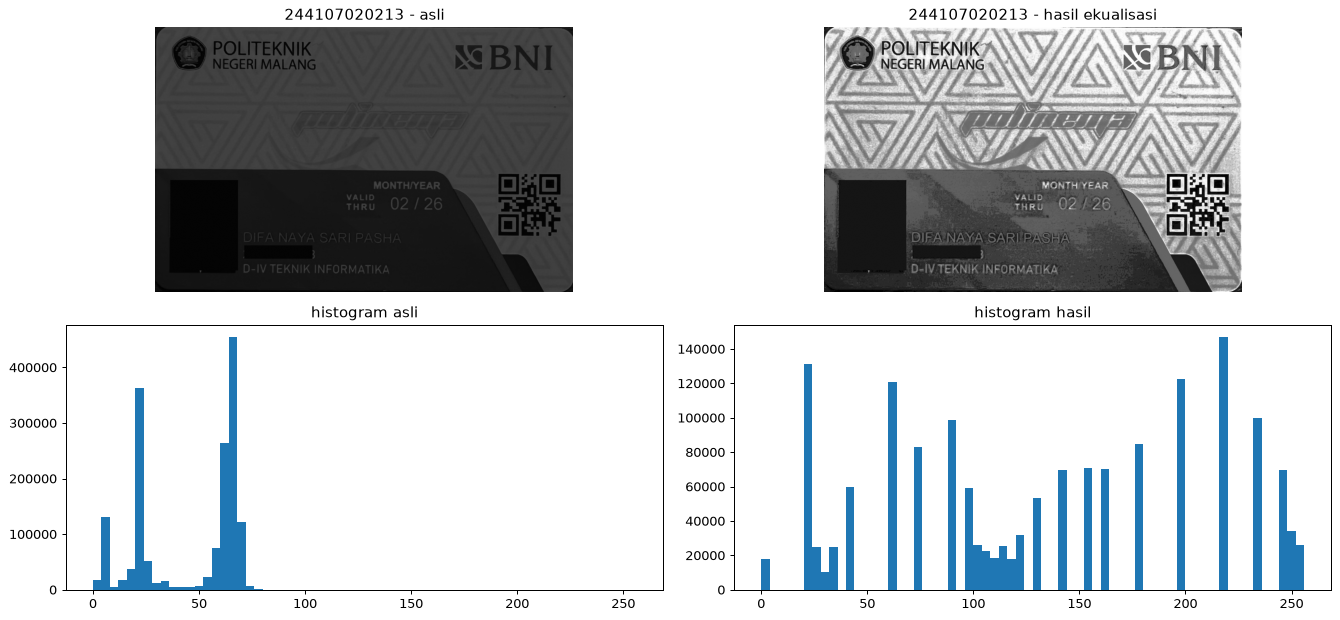

In [16]:
ktm = cv.imread(BASE + '/KTM1a.jpg', cv.IMREAD_GRAYSCALE)
he  = histogram_equalization(ktm)
print('PSNR KTM1a asli vs hasil ekualisasi : %.2f dB' % PSNR(ktm, he))

plt.figure(figsize=(15, 7))
plt.subplot(2, 2, 1)
plt.imshow(ktm, cmap='gray', vmin=0, vmax=255)
plt.title(NIM + ' - asli')
plt.axis('off')
plt.subplot(2, 2, 2)
plt.imshow(he, cmap='gray', vmin=0, vmax=255)
plt.title(NIM + ' - hasil ekualisasi')
plt.axis('off')
plt.subplot(2, 2, 3)
plt.hist(ktm.ravel(), bins=64, range=(0, 256))
plt.title('histogram asli')
plt.subplot(2, 2, 4)
plt.hist(he.ravel(), bins=64, range=(0, 256))
plt.title('histogram hasil')
plt.tight_layout()
plt.show()

PSNR ngukur kemiripan piksel sama citra asli, bukan seberapa jelas citranya. Ekualisasi sengaja
ngubah hampir semua nilai piksel, jadi MSE-nya besar dan PSNR-nya turun. Padahal secara visual
hasilnya justru lebih jelas. Jadi PSNR nggak bisa dipakai sendirian buat nilai keterbacaan citra.

**2. Ekualisasi lokal dengan CLAHE pada KTM1a.jpg.**

(a) Bandingkan CLAHE dengan ekualisasi global; (b) coba tiga nilai `clipLimit` lain di sekitar
nilai `PARAM['clip']`.

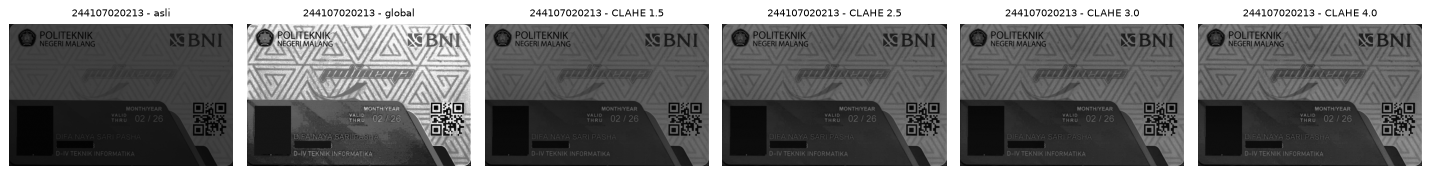

In [17]:
ktm = cv.imread(BASE + '/KTM1a.jpg', cv.IMREAD_GRAYSCALE)
global_he = cv.equalizeHist(ktm)
cla = cv.createCLAHE(clipLimit=PARAM['clip'],
                     tileGridSize=(PARAM['tile'], PARAM['tile'])).apply(ktm)

kandidat = [max(1.0, PARAM['clip'] - 1.0), PARAM['clip'],
            PARAM['clip'] + 0.5, PARAM['clip'] + 1.5]
judul = ['asli', 'global']
imgs  = [ktm, global_he]
for cl in kandidat:
    imgs.append(cv.createCLAHE(clipLimit=cl,
                               tileGridSize=(PARAM['tile'], PARAM['tile'])).apply(ktm))
    judul.append('CLAHE %.1f' % cl)

plt.figure(figsize=(16, 4))
for i, (im, t) in enumerate(zip(imgs, judul), 1):
    plt.subplot(1, len(imgs), i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(NIM + ' - ' + t, fontsize=8)
    plt.axis('off')
plt.tight_layout()
plt.show()

CLAHE ningkatin kontras secara lokal per tile, jadi area gelap yang kecil tetap kena pencerahan
tanpa bikin area terang jadi putih semua. Makanya NIM dan nama di kartu lebih kebaca di CLAHE
dibanding ekualisasi global.

Soal `clipLimit`: kekecilan bikin kontras kurang naik, kegedean malah munculin noise/bintik di area
datar. Nilai paling pas biasanya di sekitar `PARAM['clip']`, dan bagian yang duluan keliatan berisik
kalau `clipLimit` dinaikin itu area datar kayak latar kartu.

## E-3 Tugas Praktikum Dithering

### Fungsi Floyd-Steinberg (error diffusion)

In [18]:
def floyd_steinberg(gray, L=2):
    img  = gray.astype(np.float32).copy()
    step = 255.0 / (L - 1)
    H, W = img.shape
    for y in range(H):
        for x in range(W):
            lama  = img[y, x]
            baru  = np.round(lama / step) * step      # warna palet terdekat
            img[y, x] = baru
            error = lama - baru
            if x + 1 < W:              img[y,   x + 1] += error * 7 / 16
            if x > 0     and y + 1 < H: img[y + 1, x - 1] += error * 3 / 16
            if y + 1 < H:              img[y + 1, x    ] += error * 5 / 16
            if x + 1 < W and y + 1 < H: img[y + 1, x + 1] += error * 1 / 16
    return np.clip(img, 0, 255).astype(np.uint8)


def floyd_steinberg_warna(bgr, L=2):
    # citra berwarna: jalankan fungsi yang sama 3x, sekali per kanal B, G, R
    return cv.merge([floyd_steinberg(bgr[:, :, i], L) for i in range(3)])

### Tahap 1 - citra contoh `lena.jpg`

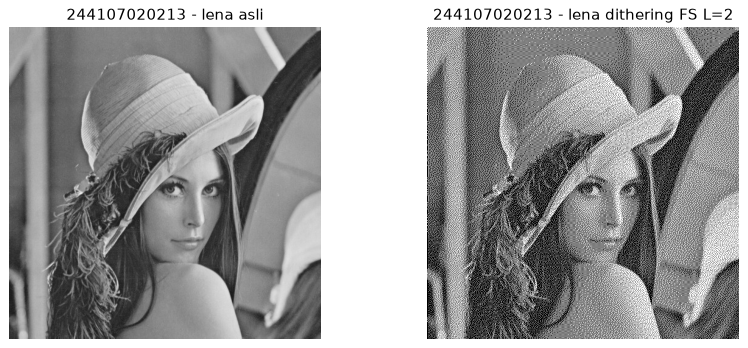

In [19]:
lena = cv.imread(CONTOH + '/lena.jpg', cv.IMREAD_GRAYSCALE)
dith = floyd_steinberg(lena, 2)
tampil(lena, dith, NIM + ' - lena asli', NIM + ' - lena dithering FS L=2')

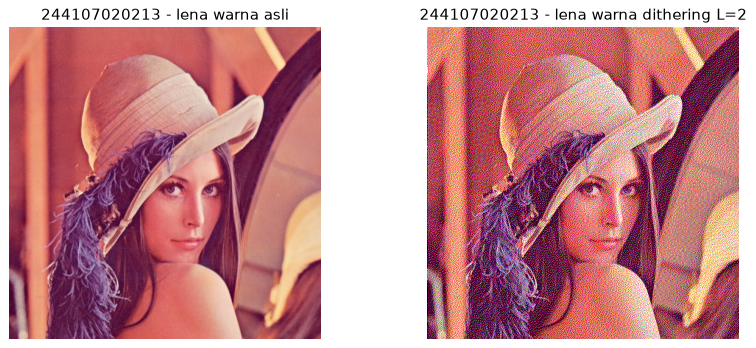

In [20]:
# contoh citra berwarna
bgr  = cv.imread(CONTOH + '/lena.jpg')
dw   = floyd_steinberg_warna(bgr, 2)
tampil(bgr, dw, NIM + ' - lena warna asli', NIM + ' - lena warna dithering L=2')

### Tahap 2 - citra KTM sendiri `KTM1b.jpg` dengan `PARAM['L']` level

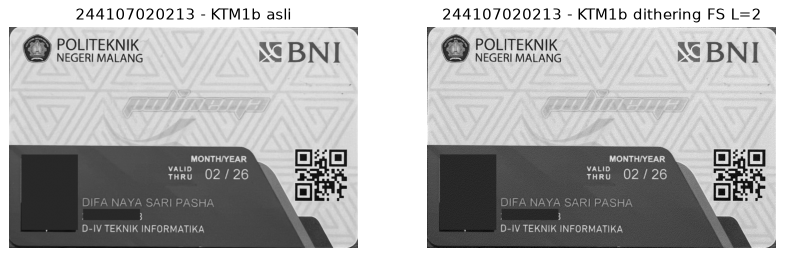

In [21]:
ktm  = cv.imread(BASE + '/KTM1b.jpg', cv.IMREAD_GRAYSCALE)
dith = floyd_steinberg(ktm, PARAM['L'])
tampil(ktm, dith, NIM + ' - KTM1b asli',
       NIM + ' - KTM1b dithering FS L=' + str(PARAM['L']))

### Dithering setelah Histogram Equalization

Ubah citra menjadi grayscale, terapkan histogram equalization, lalu dithering Floyd-Steinberg.
Bandingkan dengan dithering langsung tanpa ekualisasi.

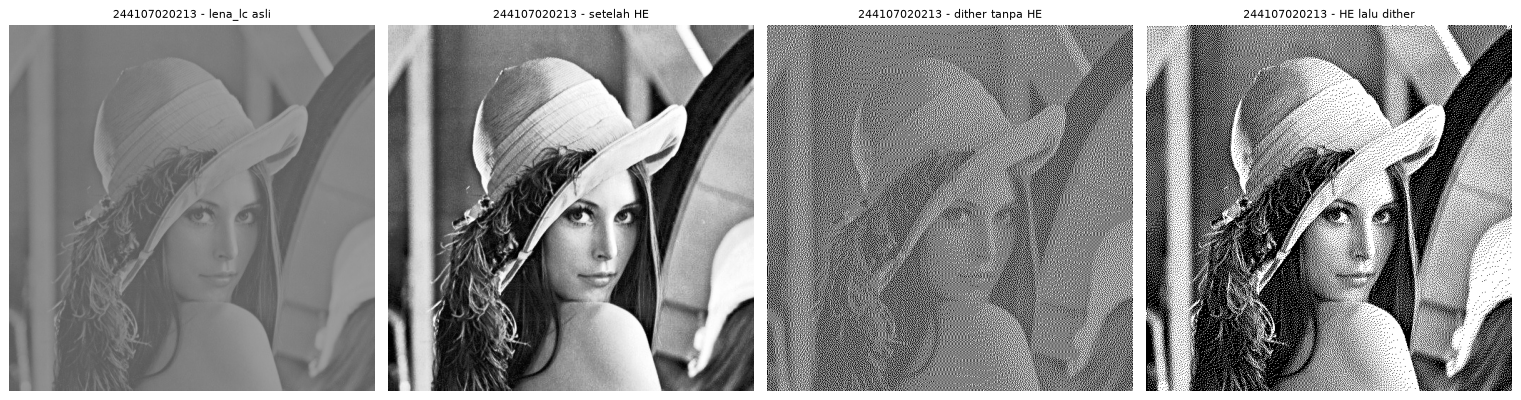

In [22]:
lc = cv.imread(CONTOH + '/lena_lc.jpg', cv.IMREAD_GRAYSCALE)
he = cv.equalizeHist(lc)
judul = ['lena_lc asli', 'setelah HE', 'dither tanpa HE', 'HE lalu dither']
imgs  = [lc, he, floyd_steinberg(lc, 2), floyd_steinberg(he, 2)]
plt.figure(figsize=(17, 4.5))
for i, (im, t) in enumerate(zip(imgs, judul), 1):
    plt.subplot(1, 4, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(NIM + ' - ' + t, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

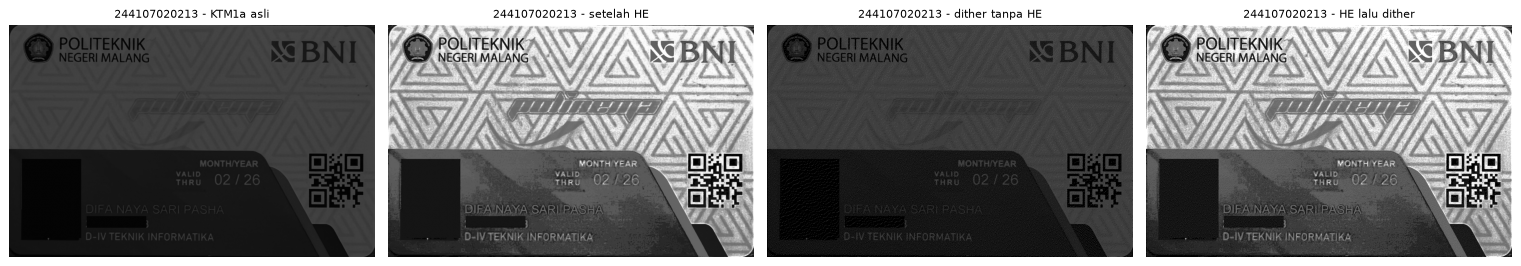

In [23]:
ktm = cv.imread(BASE + '/KTM1a.jpg', cv.IMREAD_GRAYSCALE)
he  = cv.equalizeHist(ktm)
judul = ['KTM1a asli', 'setelah HE', 'dither tanpa HE', 'HE lalu dither']
imgs  = [ktm, he, floyd_steinberg(ktm, PARAM['L']), floyd_steinberg(he, PARAM['L'])]
plt.figure(figsize=(17, 4.5))
for i, (im, t) in enumerate(zip(imgs, judul), 1):
    plt.subplot(1, 4, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(NIM + ' - ' + t, fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

Di KTM, urutan **equalization dulu baru dithering** bikin teks lebih kebaca. Ekualisasi ngerenggangin
kontras dulu jadi beda tulisan sama latar kartu makin besar, baru dithering tinggal bikin pola titik.
Kalau dithering langsung tanpa ekualisasi, kontrasnya kekecilan jadi tulisan dan latar jatuh di level
palet yang sama dan nyatu.

---
**SELAMAT BELAJAR**